# 12 · Classical causal inference methods

Workflow used throughout (the *causal reasoning workflow*): **(1)** state the causal question, **(2)** draw the DAG and name the estimand, **(3)** check identification (back-door set, overlap), **(4)** estimate with several methods, **(5)** refute / stress-test.

* **Question:** what is the effect of a tract being tribal (`T`) on `y_poi` (log POIs per 100 buildings)? Estimand: **ATT** (effect on tribal tracts).
* **Adjustment set** (from notebook 11): region, rurality / urbanity (density), plus SVI, CVI and tract size as extra covariates.
* Methods: propensity-score matching and stratification, inverse-propensity weighting, doubly robust (AIPW), then regression discontinuity and difference-in-differences.

All observational estimates are valid only if there are no unmeasured confounders. Needs `model_frame.parquet` from notebook 06.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pathlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.api as sm, statsmodels.formula.api as smf
from scipy import stats

ROOT = pathlib.Path.cwd().resolve(); ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT
OUT = ROOT / "analysis_outputs"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
SEED = 42
rng = np.random.default_rng(SEED)
f = pd.read_parquet(OUT / "model_frame.parquet")      # built in notebook 06
rmse = lambda a, b: float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.neighbors import NearestNeighbors
d = f.dropna(subset=["y_poi", "svi", "log_pop_density"]).reset_index(drop=True)
cov = ["rural", "log_pop_density", "svi", "cvi", "log_area_km2", "log_road_density"]
d[cov] = d[cov].fillna(d[cov].median())
X = pd.concat([d[cov], pd.get_dummies(d.region, drop_first=True, dtype=float)], axis=1)
Xs = ((X - X.mean()) / X.std()).values
T = d.tribal.values; Y = d.y_poi.values
print(f"n={len(d)}  treated={T.sum()}  controls={(1 - T).sum()}")

n=9706  treated=872  controls=8834


## 1 · Propensity score and overlap

21.0% of tracts fall in the treated 1-99% logit range (shaded)


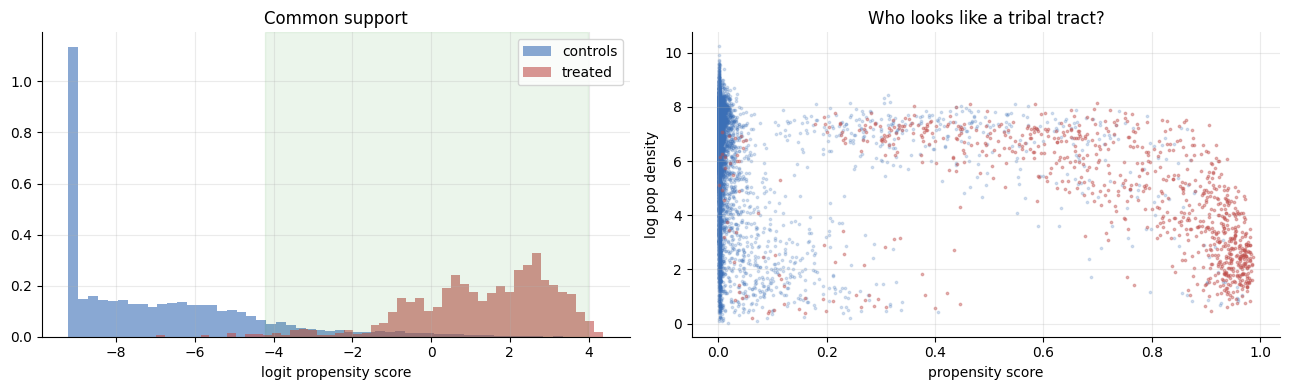

In [2]:
ps_model = LogisticRegression(max_iter=2000, C=1.0)
ps = cross_val_predict(ps_model, Xs, T, cv=KFold(5, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
ps = np.clip(ps, 1e-4, 1 - 1e-4); logit = np.log(ps / (1 - ps))
def smd(x, t, w=None):
    w = np.ones_like(x) if w is None else w
    m1 = np.average(x[t == 1], weights=w[t == 1]); m0 = np.average(x[t == 0], weights=w[t == 0])
    v = (x[t == 1].var() + x[t == 0].var()) / 2; return (m1 - m0) / np.sqrt(v)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for t_, c, l in ((0, "#3b6fb6", "controls"), (1, "#c0504d", "treated")): ax[0].hist(logit[T == t_], bins=50, alpha=.6, color=c, label=l, density=True)
ax[0].legend(); ax[0].set_xlabel("logit propensity score"); ax[0].set_title("Common support")
lo, hi = np.percentile(logit[T == 1], [1, 99]); ax[0].axvspan(lo, hi, color="g", alpha=.08)
common = (logit >= lo) & (logit <= hi); print(f"{common.mean():.1%} of tracts fall in the treated 1-99% logit range (shaded)")
ax[1].scatter(ps[T == 0], d.log_pop_density[T == 0], s=3, alpha=.2, color="#3b6fb6"); ax[1].scatter(ps[T == 1], d.log_pop_density[T == 1], s=3, alpha=.4, color="#c0504d"); ax[1].set(xlabel="propensity score", ylabel="log pop density", title="Who looks like a tribal tract?")
plt.tight_layout(); plt.show()

**Comment:** the shaded band is where comparison is credible: controls far to the left (low propensity: big Texas / Arizona cities) have no tribal look-alike, so matching and weighting will effectively ignore them.

## 2 · Propensity-score matching (1-NN, caliper, with replacement) -> ATT

                  before  after
rural               0.73   0.08
log_pop_density     0.92   0.20
svi                 0.20   0.09
cvi                 0.36   0.22
log_area_km2        0.81   0.21
log_road_density    0.82   0.06
eastern-wa          0.15   0.02
maricopa-az         0.43   0.01
northern-ca         0.24   0.04
south-central-tx    2.03   0.03
PSM ATT = +0.170   (99.3% of treated matched; 259 distinct controls used)


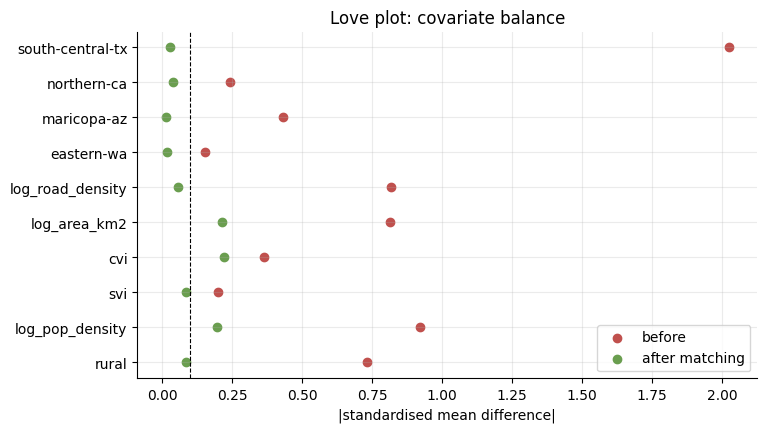

In [3]:
def psm_att(logit, T, Y, caliper_sd=.2, seed=SEED):
    tr_i, co_i = np.where(T == 1)[0], np.where(T == 0)[0]
    nn = NearestNeighbors(n_neighbors=1).fit(logit[co_i, None]); dist, idx = nn.kneighbors(logit[tr_i, None])
    ok = dist[:, 0] <= caliper_sd * logit.std()
    m_t, m_c = tr_i[ok], co_i[idx[ok, 0]]
    return float((Y[m_t] - Y[m_c]).mean()), m_t, m_c, ok.mean()
att_psm, m_t, m_c, kept = psm_att(logit, T, Y)
cols = list(X.columns)
bal = pd.DataFrame({"before": [smd(X[c].values, T) for c in cols],
                    "after": [smd(np.r_[X[c].values[m_t], X[c].values[m_c]], np.r_[np.ones(len(m_t)), np.zeros(len(m_c))]) for c in cols]}, index=cols)
print(bal.abs().round(2).to_string())
print(f"PSM ATT = {att_psm:+.3f}   ({kept:.1%} of treated matched; {len(set(m_c))} distinct controls used)")
fig, ax = plt.subplots(figsize=(8, 4.5)); y_ = np.arange(len(cols))
ax.scatter(bal.before.abs(), y_, label="before", color="#c0504d"); ax.scatter(bal.after.abs(), y_, label="after matching", color="#6a9e4f")
ax.axvline(.1, color="k", ls="--", lw=.8); ax.set_yticks(y_); ax.set_yticklabels(cols); ax.set_xlabel("|standardised mean difference|"); ax.legend(); ax.set_title("Love plot: covariate balance"); plt.show()

**Comment:** before matching the groups differ hugely (|SMD| 2.03 for the Texas indicator, 0.92 for density, 0.82 for road density, 0.73 for rurality). After matching most covariates fall below the 0.1 rule of thumb, but density, CVI and tract area stay near 0.2, so some imbalance remains (the regression and doubly robust estimators below adjust for it).

## 3 · Stratification and inverse-propensity weighting (IPW)

                  before  after  after IPW
rural               0.73   0.08       0.10
log_pop_density     0.92   0.20       0.14
svi                 0.20   0.09       0.06
cvi                 0.36   0.22       0.19
log_area_km2        0.81   0.21       0.14
log_road_density    0.82   0.06       0.00
eastern-wa          0.15   0.02       0.00
maricopa-az         0.43   0.01       0.01
northern-ca         0.24   0.04       0.02
south-central-tx    2.03   0.03       0.01
stratification (5 strata) ATT = +0.099   |   IPW ATT = +0.089


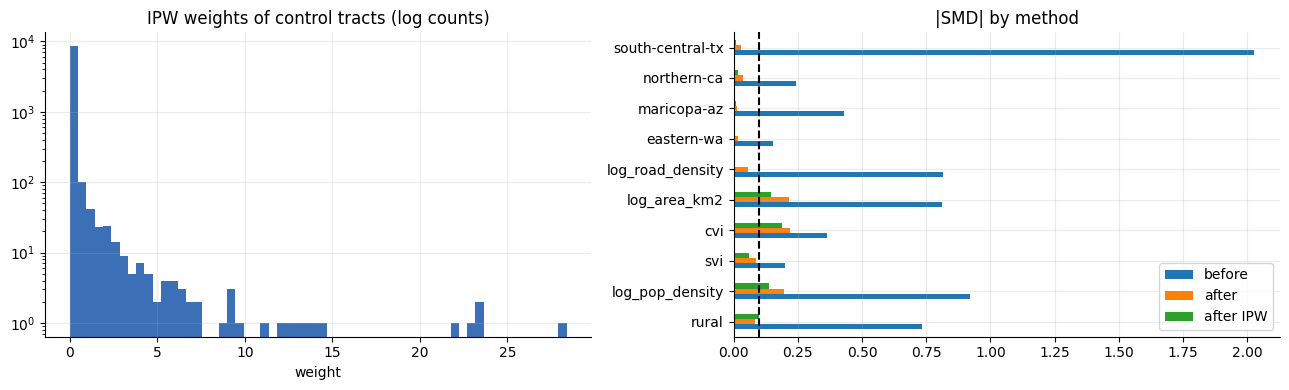

effective sample size of weighted controls: 109 of 8834


In [4]:
def strat_att(ps, T, Y, k=5):
    q = pd.qcut(ps[T == 1], k, labels=False, duplicates="drop"); edges = np.quantile(ps[T == 1], np.linspace(0, 1, k + 1)); edges[0], edges[-1] = 0, 1
    b = np.clip(np.digitize(ps, edges[1:-1]), 0, k - 1); res, w = [], []
    for s_ in range(k):
        m = b == s_
        if (T[m] == 1).sum() > 0 and (T[m] == 0).sum() > 0: res.append(Y[m & (T == 1)].mean() - Y[m & (T == 0)].mean()); w.append((m & (T == 1)).sum())
    return float(np.average(res, weights=w))
def ipw_att(ps, T, Y, trim=.99):
    w = np.where(T == 1, 1.0, ps / (1 - ps)); w = np.where((T == 0) & (ps > trim), 0, w)       # ATT weights; drop controls with extreme odds
    return float(np.average(Y[T == 1]) - np.average(Y[T == 0], weights=w[T == 0])), w
att_str = strat_att(ps, T, Y); att_ipw, w_ = ipw_att(ps, T, Y)
bal["after IPW"] = [smd(X[c].values, T, w_) for c in cols]
print(bal.abs().round(2).to_string())
print(f"stratification (5 strata) ATT = {att_str:+.3f}   |   IPW ATT = {att_ipw:+.3f}")
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(w_[T == 0][w_[T == 0] > 0], bins=60, color="#3b6fb6"); ax[0].set_yscale("log"); ax[0].set_title("IPW weights of control tracts (log counts)"); ax[0].set_xlabel("weight")
bal[["before", "after", "after IPW"]].abs().plot.barh(ax=ax[1]); ax[1].axvline(.1, color="k", ls="--"); ax[1].set_title("|SMD| by method")
plt.tight_layout(); plt.show()
print(f"effective sample size of weighted controls: {w_[T == 0].sum() ** 2 / (w_[T == 0] ** 2).sum():.0f} of {(T == 0).sum()}")

**Comment:** IPW balances every covariate to |SMD| <= 0.19, but it does so by up-weighting the few controls that look tribal: the effective sample size of the controls is only 109 of 8,834 (long weight tail), so its estimate is noisy. Check that number before trusting a weighted estimate.

## 4 · Doubly robust estimation (AIPW) for the ATT
Correct if *either* the outcome model *or* the propensity model is right. Cross-fitted so the flexible learner does not overfit its own predictions.

                                  ATT     SE
naive difference               -0.383    NaN
OLS adjusted                    0.131  0.045
PSM                             0.170  0.072
stratification                  0.099  0.059
IPW                             0.089  0.065
DR + ridge outcome              0.104  0.041
DR + gradient boosting outcome  0.090  0.044


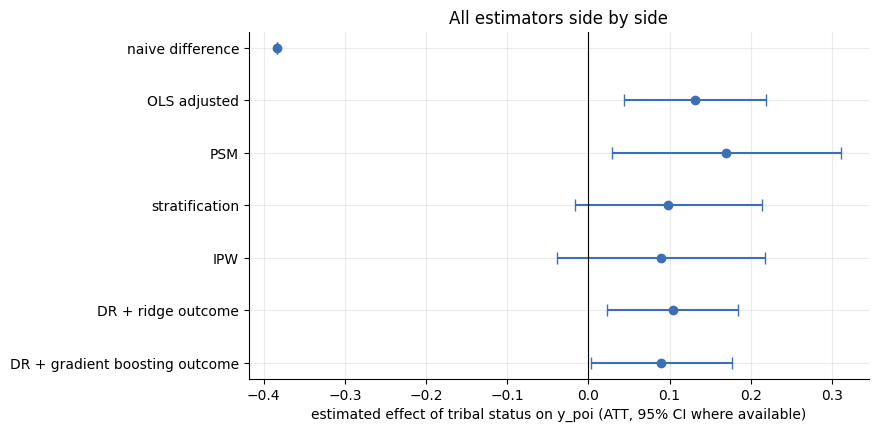

In [5]:
kf = KFold(5, shuffle=True, random_state=SEED)
def mu0_crossfit(model_fn):
    mu0 = np.zeros(len(Y))
    for tr_, te_ in kf.split(Xs):
        m = model_fn().fit(Xs[tr_][T[tr_] == 0], Y[tr_][T[tr_] == 0]); mu0[te_] = m.predict(Xs[te_])
    return mu0
def aipw_att(mu0, ps, T, Y):
    p1 = T.mean(); r = Y - mu0; w = ps / (1 - ps)
    psi = (T * r - (1 - T) * w * r) / p1
    tau = psi.mean(); psi = psi - tau * T / p1
    return float(tau), float(psi.std() / np.sqrt(len(Y)))
res_dr = {}
for name, fn in {"DR + ridge outcome": lambda: Ridge(alpha=1.0), "DR + gradient boosting outcome": lambda: HistGradientBoostingRegressor(max_depth=3, learning_rate=.05, max_iter=200, random_state=SEED)}.items():
    res_dr[name] = aipw_att(mu0_crossfit(fn), np.clip(ps, .01, .99), T, Y)
naive = Y[T == 1].mean() - Y[T == 0].mean()
ols = smf.ols("Y ~ T + " + " + ".join(cov) + " + C(region)", d.assign(Y=Y, T=T)).fit(cov_type="HC3")
rows = {"naive difference": (naive, np.nan), "OLS adjusted": (ols.params["T"], ols.bse["T"]), "PSM": (att_psm, np.nan), "stratification": (att_str, np.nan), "IPW": (att_ipw, np.nan), **res_dr}
# bootstrap SEs for the cheap estimators
bs = []
for _ in range(150):
    i = rng.integers(0, len(Y), len(Y)); Xb, Tb, Yb = Xs[i], T[i], Y[i]
    pb = LogisticRegression(max_iter=500).fit(Xb, Tb).predict_proba(Xb)[:, 1]; pb = np.clip(pb, 1e-4, 1 - 1e-4); lb = np.log(pb / (1 - pb))
    bs.append((psm_att(lb, Tb, Yb)[0], strat_att(pb, Tb, Yb), ipw_att(pb, Tb, Yb)[0]))
bs = np.array(bs).std(axis=0)
for k, s_ in zip(["PSM", "stratification", "IPW"], bs): rows[k] = (rows[k][0], s_)
tab = pd.DataFrame(rows, index=["ATT", "SE"]).T
print(tab.round(3).to_string())
fig, ax = plt.subplots(figsize=(8, 4.5)); y_ = np.arange(len(tab))[::-1]
ax.errorbar(tab.ATT, y_, xerr=1.96 * tab.SE.fillna(0), fmt="o", color="#3b6fb6", capsize=4); ax.axvline(0, color="k", lw=.8); ax.set_yticks(y_); ax.set_yticklabels(tab.index)
ax.set_xlabel("estimated effect of tribal status on y_poi (ATT, 95% CI where available)"); ax.set_title("All estimators side by side"); plt.show()

**Comment:** the naive gap (-0.38) reverses sign once we compare like with like: every adjusted estimator gives a small *positive* ATT (+0.09 to +0.17; OLS +0.13, SE 0.045; doubly robust +0.09 to +0.10), i.e. comparable tribal tracts have slightly *more* POIs per building. The sign and rough size agree across six methods, which is reassuring, but the answer is sensitive to the adjustment set: notebook 11 (region x rural strata only) found about -0.04, and the ANCOVA in notebook 06 about -0.07. So the honest summary is 'small, with a sign that depends on how density is controlled', all conditional on no unmeasured confounding.

## 5 · Refutation: placebo treatment
If we randomly permute the treatment labels, a sound pipeline should find an effect near 0.

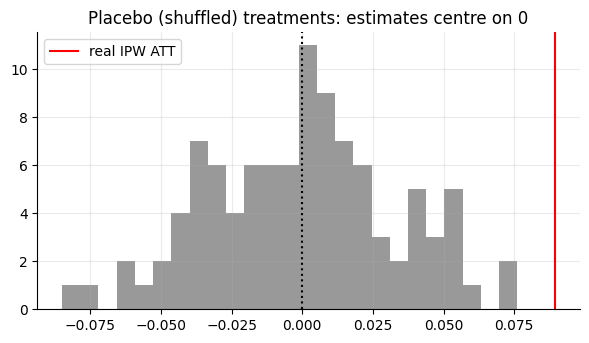

placebo mean -0.001, sd 0.033


In [6]:
pl = []
for _ in range(100):
    Tp = rng.permutation(T); pp = LogisticRegression(max_iter=300).fit(Xs, Tp).predict_proba(Xs)[:, 1]; pp = np.clip(pp, 1e-4, 1 - 1e-4)
    pl.append(ipw_att(pp, Tp, Y)[0])
fig, ax = plt.subplots(figsize=(7, 3.6)); ax.hist(pl, bins=25, color="#999"); ax.axvline(att_ipw, color="r", label="real IPW ATT"); ax.axvline(0, color="k", ls=":"); ax.legend(); ax.set_title("Placebo (shuffled) treatments: estimates centre on 0"); plt.show()
print(f"placebo mean {np.mean(pl):+.3f}, sd {np.std(pl):.3f}")

**Comment:** placebo effects scatter around 0, so the pipeline does not manufacture effects from noise. Passing a placebo is necessary but does not prove the absence of unmeasured confounding.

## 6 · Regression discontinuity design (RDD)

RDD needs a **cutoff in a running variable that assigns treatment**. We have none for mapping coverage, so this is an *illustrative / diagnostic* RDD: CDC's SVI documentation flags tracts with percentile rank >= 0.75 as "high vulnerability". Does `y_poi` jump at that line? Any jump would be surprising (nobody maps differently because of the flag), so a null result also acts as a **continuity check** of the design.

       jump     se     n
0.05  0.091  0.131  1162
0.08  0.124  0.104  1828
0.10  0.123  0.092  2279
0.15  0.141  0.076  3475
0.20  0.121  0.066  4632
0.25  0.090  0.059  5856


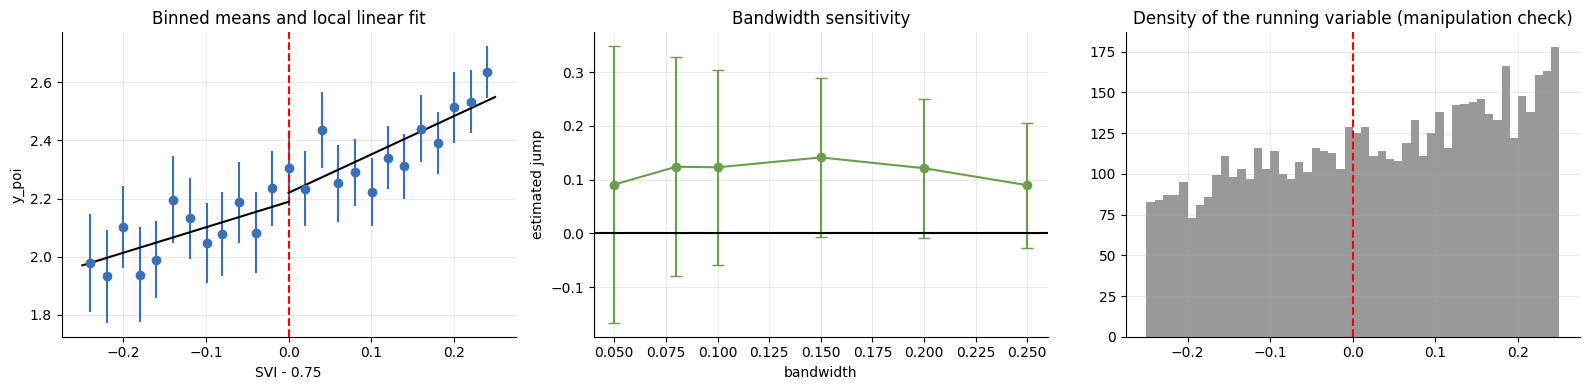

jump is within +-1.96 SE of zero at bandwidths: [0.05, 0.08, 0.1, 0.15, 0.2, 0.25]


In [7]:
r = d.assign(x=d.svi - 0.75); r = r[(r.x.abs() <= .25)]
def rd(h, df):
    w = df[df.x.abs() <= h].copy(); w["D"] = (w.x >= 0).astype(int); w["k"] = 1 - w.x.abs() / h
    m = smf.wls("y_poi ~ D + x + D:x", w, weights=w.k).fit(cov_type="HC3"); return m.params["D"], m.bse["D"], len(w)
bw = [.05, .08, .1, .15, .2, .25]
res = pd.DataFrame([rd(h, r) for h in bw], index=bw, columns=["jump", "se", "n"])
print(res.round(3).to_string())
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
b = r.assign(bin=pd.cut(r.x, np.linspace(-.25, .25, 26))).groupby("bin").agg(x=("x", "mean"), y=("y_poi", "mean"), se=("y_poi", lambda s: s.std() / np.sqrt(len(s))))
ax[0].errorbar(b.x, b.y, yerr=1.96 * b.se, fmt="o", color="#3b6fb6"); ax[0].axvline(0, color="r", ls="--")
for side in (r[r.x < 0], r[r.x >= 0]): ax[0].plot(np.sort(side.x), np.polyval(np.polyfit(side.x, side.y_poi, 1), np.sort(side.x)), color="k")
ax[0].set(xlabel="SVI - 0.75", ylabel="y_poi", title="Binned means and local linear fit")
ax[1].errorbar(res.index, res.jump, yerr=1.96 * res.se, fmt="o-", color="#6a9e4f", capsize=4); ax[1].axhline(0, color="k"); ax[1].set(xlabel="bandwidth", ylabel="estimated jump", title="Bandwidth sensitivity")
ax[2].hist(r.x, bins=50, color="#999"); ax[2].axvline(0, color="r", ls="--"); ax[2].set_title("Density of the running variable (manipulation check)")
plt.tight_layout(); plt.show()
print("jump is within +-1.96 SE of zero at bandwidths:", [h for h, row in res.iterrows() if abs(row.jump) <= 1.96 * row.se])

**Comment:** the estimated jump at the 0.75 line is +0.09 to +0.14 across bandwidths, positive throughout but never significant at the 5% level (largest |t| about 1.9 at bandwidth 0.15-0.2), and the running variable has a smooth density with no sign of manipulation. This is weak evidence at most; it is a diagnostic, not a policy finding, because no mapping intervention is triggered at this cutoff.

## 7 · Difference-in-differences (DID) - simulated panel

DID needs outcomes before and after an intervention for treated and comparison groups. The tract table is a single snapshot, so we **simulate** a panel with a known effect to show the method and its key assumption (parallel trends). *This is a demonstration, not a finding about the data.*

truth 1.50 | parallel trends hold: 1.43 (se 0.03) | violated: 2.18 (se 0.03)


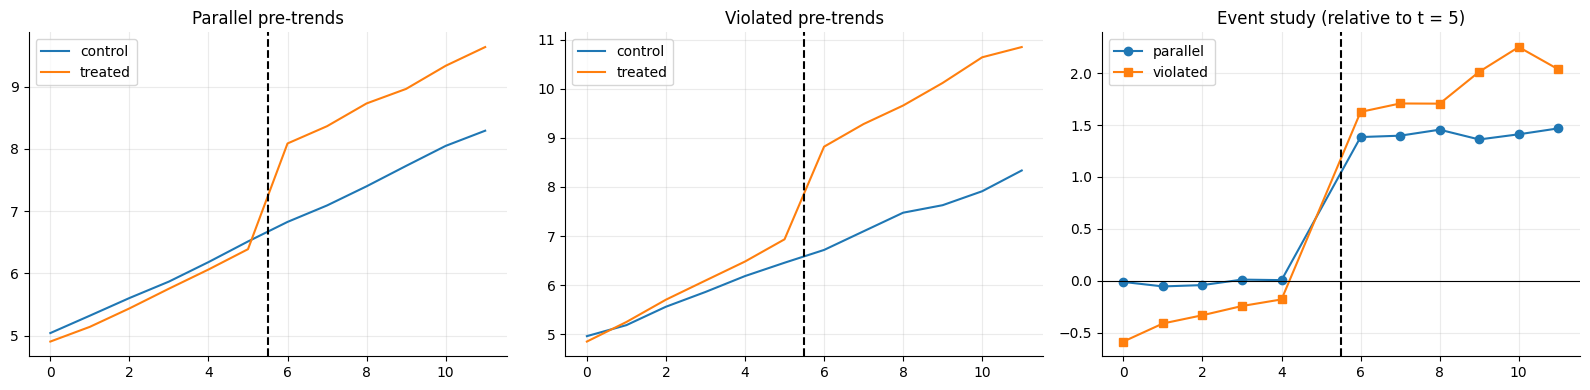

In [8]:
N, P, t0, TRUE = 400, 12, 6, 1.5
unit = np.repeat(np.arange(N), P); time = np.tile(np.arange(P), N); treated = (unit < N // 2).astype(int)
ufe = rng.normal(0, 1, N)[unit]; trend = .3 * time
def panel(diff_trend=0.0):
    y = 5 + ufe + trend + diff_trend * time * treated + TRUE * treated * (time >= t0) + rng.normal(0, .6, N * P)
    return pd.DataFrame({"unit": unit, "time": time, "treated": treated, "post": (time >= t0).astype(int), "y": y})
def did(df_):
    m = smf.ols("y ~ treated * post", df_).fit(cov_type="cluster", cov_kwds={"groups": df_.unit}); return m.params["treated:post"], m.bse["treated:post"]
ok_, bad_ = panel(0.0), panel(0.12)                      # parallel trends hold / violated
(ok_est, ok_se), (bad_est, bad_se) = did(ok_), did(bad_)
print(f"truth {TRUE:.2f} | parallel trends hold: {ok_est:.2f} (se {ok_se:.2f}) | violated: {bad_est:.2f} (se {bad_se:.2f})")
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a_, df_, ttl in ((ax[0], ok_, "Parallel pre-trends"), (ax[1], bad_, "Violated pre-trends")):
    g = df_.groupby(["time", "treated"]).y.mean().unstack(); a_.plot(g.index, g[0], label="control"); a_.plot(g.index, g[1], label="treated"); a_.axvline(t0 - .5, color="k", ls="--"); a_.set_title(ttl); a_.legend()
def event_study(df_):
    m = smf.ols("y ~ treated * C(time, Treatment(reference=5))", df_).fit(); k = [c for c in m.params.index if c.startswith("treated:")]
    return pd.Series(m.params[k].values, index=[int(c.split("[T.")[1].rstrip("]")) for c in k]).sort_index()
ax[2].plot(event_study(ok_), "o-", label="parallel"); ax[2].plot(event_study(bad_), "s-", label="violated"); ax[2].axhline(0, color="k", lw=.8); ax[2].axvline(t0 - .5, color="k", ls="--"); ax[2].legend(); ax[2].set_title("Event study (relative to t = 5)")
plt.tight_layout(); plt.show()

**Comment:** when pre-trends are parallel DID recovers the true +1.5; when the treated group was already trending up, DID is biased (the event-study coefficients drift before the intervention, which is the diagnostic you would check in real data).

## 8 · Summary of classical methods

| Method | Needs | Used here? |
|---|---|---|
| Matching / stratification / IPW | measured confounders + overlap | yes, real data |
| Doubly robust | outcome model + propensity model | yes, real data |
| RDD | a cutoff that assigns treatment | diagnostic only (SVI >= 0.75) |
| DID | before/after panel | simulation only (no panel in the tract table) |

**Take-away for the challenge:** the raw tribal gap in POI density (-0.38) is mostly a *where-you-live* effect: comparing tracts with similar region, rurality, density and vulnerability gives small adjusted effects whose sign depends on the adjustment set (about -0.07 to +0.17 across notebooks 06, 11 and 12). That is useful context for the bias write-up, but the leaderboard score still depends on predicting the hidden gap well.